In [7]:
import pandas as pd
import numpy as np

In [12]:
df=pd.read_csv(r'C:\Users\smk25\OneDrive\Documents\Customer Segmentation for Targeted Marketing\dataset\cleaned_customer_data.csv')

In [13]:
#feature engineering
#Feature 1 – Total Spending
spending_columns = [
    'MntWines',
    'MntFruits',
    'MntMeatProducts',
    'MntFishProducts',
    'MntSweetProducts',
    'MntGoldProds'
]

df['Total_Spending'] = df[spending_columns].sum(axis=1)

print(df[['ID', 'Total_Spending']].head())

     ID  Total_Spending
0  5524            1617
1  2174              27
2  4141             776
3  6182              53
4  5324             422


In [16]:
#Feature 2 – Total Purchases
purchase_columns = [
    'NumWebPurchases',
    'NumCatalogPurchases',
    'NumStorePurchases'
]

df['Total_Purchases'] = df[purchase_columns].sum(axis=1)

print(df[['ID', 'Total_Purchases']].head())

     ID  Total_Purchases
0  5524               22
1  2174                4
2  4141               20
3  6182                6
4  5324               14


In [15]:
#Feature 3 – Family Size
df['Family_Size'] = (
    df['Kidhome'] + df['Teenhome'] + 1
)

print(df[['ID', 'Kidhome', 'Teenhome', 'Family_Size']].head())

     ID  Kidhome  Teenhome  Family_Size
0  5524        0         0            1
1  2174        1         1            3
2  4141        0         0            1
3  6182        1         0            2
4  5324        1         0            2


In [17]:
# Convert customer enrollment date
df['Dt_Customer'] = pd.to_datetime(
    df['Dt_Customer'],
    format='%Y-%m-%d'
)


In [18]:
#. Feature 4 – Customer Tenure
reference_date = df['Dt_Customer'].max() + pd.Timedelta(days=1)

df['Customer_Tenure'] = (
    reference_date - df['Dt_Customer']
).dt.days

print("Reference Date:", reference_date)

print(
    df[['ID', 'Dt_Customer', 'Customer_Tenure']].head()
)

Reference Date: 2014-06-30 00:00:00
     ID Dt_Customer  Customer_Tenure
0  5524  2012-09-04              664
1  2174  2014-03-08              114
2  4141  2013-08-21              313
3  6182  2014-02-10              140
4  5324  2014-01-19              162


In [19]:
#Feature 5 – Wine Spending Ratio
df['Wine_Spending_Ratio'] = np.where(
    df['Total_Spending'] > 0,
    df['MntWines'] / df['Total_Spending'],
    0
)


print(
    df[['ID', 'MntWines', 'Total_Spending',
        'Wine_Spending_Ratio']].head()
)

     ID  MntWines  Total_Spending  Wine_Spending_Ratio
0  5524       635            1617             0.392703
1  2174        11              27             0.407407
2  4141       426             776             0.548969
3  6182        11              53             0.207547
4  5324       173             422             0.409953


In [20]:
#feature scaling
model_features = [
    'Age',
    'Income',
    'Recency',
    'Family_Size',
    'Customer_Tenure',
    'MntWines',
    'MntFruits',
    'MntMeatProducts',
    'MntFishProducts',
    'MntSweetProducts',
    'MntGoldProds',
    'NumWebPurchases',
    'NumCatalogPurchases',
    'NumStorePurchases'
]

X_model = df[model_features].copy()

print("Shape:", X_model.shape)
print(X_model.head())

Shape: (2236, 14)
   Age   Income  Recency  Family_Size  Customer_Tenure  MntWines  MntFruits  \
0   57  58138.0       58            1              664       635         88   
1   60  46344.0       38            3              114        11          1   
2   49  71613.0       26            1              313       426         49   
3   30  26646.0       26            2              140        11          4   
4   33  58293.0       94            2              162       173         43   

   MntMeatProducts  MntFishProducts  MntSweetProducts  MntGoldProds  \
0              546              172                88            88   
1                6                2                 1             6   
2              127              111                21            42   
3               20               10                 3             5   
4              118               46                27            15   

   NumWebPurchases  NumCatalogPurchases  NumStorePurchases  
0                8 

In [21]:
#Apply StandardScaler
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X_model)

X_scaled = pd.DataFrame(
    X_scaled,
    columns=X_model.columns,
    index=X_model.index
)

print(X_scaled.head())

        Age    Income   Recency  Family_Size  Customer_Tenure  MntWines  \
0  1.016868  0.288947  0.306856    -1.264308         1.529793  0.983228   
1  1.273264 -0.262003 -0.383971     1.395139        -1.191143 -0.871064   
2  0.333146  0.918423 -0.798467    -1.264308        -0.206659  0.362159   
3 -1.290693 -1.182183 -0.798467     0.065416        -1.062517 -0.871064   
4 -1.034298  0.296187  1.550344     0.065416        -0.953679 -0.389661   

   MntFruits  MntMeatProducts  MntFishProducts  MntSweetProducts  \
0   1.554170         1.679746         2.461068          1.475396   
1  -0.636431        -0.713455        -0.650414         -0.631638   
2   0.572177        -0.177201         1.344595         -0.147262   
3  -0.560893        -0.651409        -0.503991         -0.583200   
4   0.421101        -0.217088         0.154911         -0.001950   

   MntGoldProds  NumWebPurchases  NumCatalogPurchases  NumStorePurchases  
0      0.845669         1.407639             2.509801          -0

In [22]:
print("Scaled Shape:", X_scaled.shape)

print("\nMean:")
print(X_scaled.mean().round(2))

print("\nStandard Deviation:")
print(X_scaled.std().round(2))

print("\nMinimum:")
print(X_scaled.min().round(2))

print("\nMaximum:")
print(X_scaled.max().round(2))

Scaled Shape: (2236, 14)

Mean:
Age                    0.0
Income                -0.0
Recency               -0.0
Family_Size           -0.0
Customer_Tenure        0.0
MntWines              -0.0
MntFruits             -0.0
MntMeatProducts       -0.0
MntFishProducts        0.0
MntSweetProducts       0.0
MntGoldProds           0.0
NumWebPurchases        0.0
NumCatalogPurchases   -0.0
NumStorePurchases     -0.0
dtype: float64

Standard Deviation:
Age                    1.0
Income                 1.0
Recency                1.0
Family_Size            1.0
Customer_Tenure        1.0
MntWines               1.0
MntFruits              1.0
MntMeatProducts        1.0
MntFishProducts        1.0
MntSweetProducts       1.0
MntGoldProds           1.0
NumWebPurchases        1.0
NumCatalogPurchases    1.0
NumStorePurchases      1.0
dtype: float64

Minimum:
Age                   -2.32
Income                -2.35
Recency               -1.70
Family_Size           -1.26
Customer_Tenure       -1.75
MntWines   

In [23]:
X_scaled.to_csv(
    r'C:\Users\smk25\OneDrive\Documents\Customer Segmentation for Targeted Marketing\dataset\customer_scaled_data.csv',
    index=False
)

In [1]:
#Step 1: Import
from sklearn.cluster import KMeans

In [26]:
#Step 2: Build initial model
kmeans = KMeans(
    n_clusters=4,
    init='k-means++',
    n_init=10,
    random_state=42
)

#Step 3: Fit and predict
cluster_labels = kmeans.fit_predict(X_scaled)

In [27]:
#Step 4: Add cluster labels
customer_segments = df.loc[X_model.index].copy()

customer_segments['Cluster'] = cluster_labels

In [28]:
#step 5 : Check cluster distribution
print(customer_segments['Cluster'].value_counts().sort_index())

Cluster
0    609
1    506
2    596
3    525
Name: count, dtype: int64


In [29]:
#Step 6: Check model details
print("Centroid Shape:", kmeans.cluster_centers_.shape)
print("Inertia:", kmeans.inertia_)

Centroid Shape: (4, 14)
Inertia: 17811.624085126972


In [30]:
#Step 7: Save results
customer_segments.to_csv(
    r'C:\Users\smk25\OneDrive\Documents\Customer Segmentation for Targeted Marketing\dataset\customer_cluster_results.csv',
    index=False
)

In [31]:
#Elbow Method
#Step 1 – Import libraries
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

In [33]:
#Step 2 – Create K value
inertia_values = []

K_range = range(1, 11)

#Step 3 – Build multiple K-Means models

for k in K_range:

    kmeans = KMeans(
        n_clusters=k,
        init='k-means++',
        n_init=10,
        random_state=42
    )

    kmeans.fit(X_scaled)

    inertia_values.append(kmeans.inertia_)

#Step 4 – Print inertia values

for k, inertia in zip(K_range, inertia_values):
    print(f"K = {k}, Inertia = {inertia:.2f}")

K = 1, Inertia = 31304.00
K = 2, Inertia = 21138.40
K = 3, Inertia = 18805.87
K = 4, Inertia = 17811.62
K = 5, Inertia = 16888.91
K = 6, Inertia = 16295.11
K = 7, Inertia = 15800.85
K = 8, Inertia = 15366.40
K = 9, Inertia = 14943.37
K = 10, Inertia = 14535.77


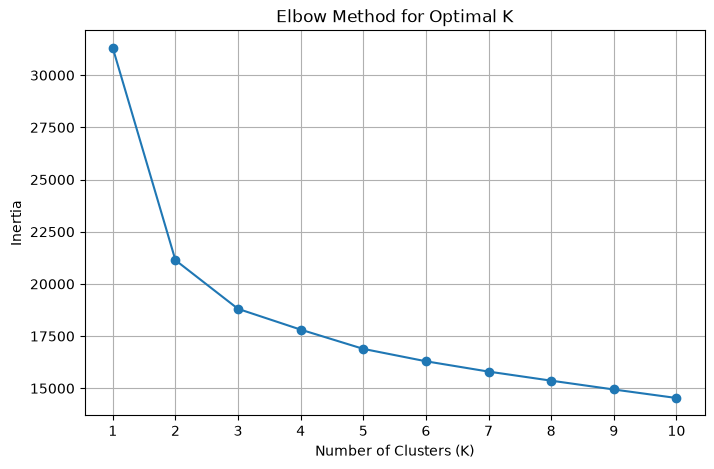

In [34]:
#Step 5 – Plot Elbow Curve

plt.figure(figsize=(8, 5))

plt.plot(
    K_range,
    inertia_values,
    marker='o'
)

plt.xlabel('Number of Clusters (K)')
plt.ylabel('Inertia')
plt.title('Elbow Method for Optimal K')

plt.xticks(K_range)
plt.grid(True)

plt.show()

In [35]:
#Silhouette Score
#Step 1 – Import libraries
from sklearn.metrics import silhouette_score

In [36]:
#Step 2 – Calculate Silhouette Score for K = 2 to 10
silhouette_values = []

K_range = range(2, 11)

for k in K_range:

    kmeans = KMeans(
        n_clusters=k,
        init='k-means++',
        n_init=10,
        random_state=42
    )

    labels = kmeans.fit_predict(X_scaled)

    score = silhouette_score(
        X_scaled,
        labels
    )

    silhouette_values.append(score)

In [37]:
#Step 3 – Print scores
for k, score in zip(K_range, silhouette_values):
    print(f"K = {k}, Silhouette Score = {score:.4f}")

K = 2, Silhouette Score = 0.3201
K = 3, Silhouette Score = 0.2173
K = 4, Silhouette Score = 0.1270
K = 5, Silhouette Score = 0.1262
K = 6, Silhouette Score = 0.1250
K = 7, Silhouette Score = 0.1090
K = 8, Silhouette Score = 0.1025
K = 9, Silhouette Score = 0.1063
K = 10, Silhouette Score = 0.1043


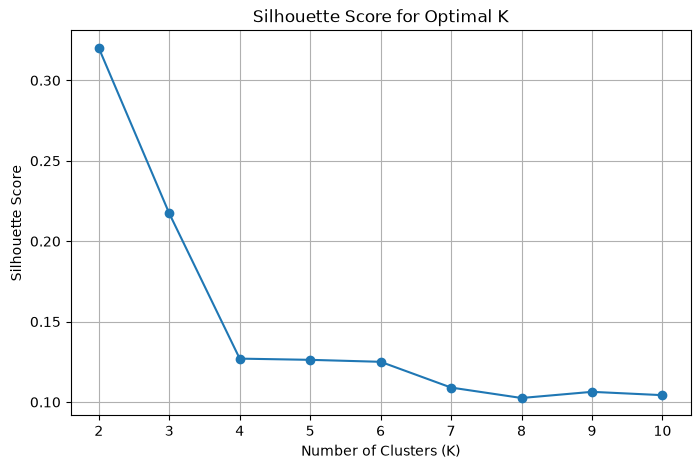

In [38]:
#Step 4 – Plot Silhouette Score graph
plt.figure(figsize=(8, 5))

plt.plot(
    K_range,
    silhouette_values,
    marker='o'
)

plt.xlabel('Number of Clusters (K)')
plt.ylabel('Silhouette Score')
plt.title('Silhouette Score for Optimal K')

plt.xticks(K_range)
plt.grid(True)

plt.show()

In [40]:
#copamre k = 2,3,4
for k in [2, 3, 4]:

    model = KMeans(
        n_clusters=k,
        init='k-means++',
        n_init=10,
        random_state=42
    )

    labels = model.fit_predict(X_scaled)

    temp_df = df.loc[X_model.index].copy()
    temp_df['Cluster'] = labels

    print(f"\nK = {k}")
    print("Silhouette Score:",
          round(silhouette_score(X_scaled, labels), 4))

    print("\nCluster Sizes:")
    print(temp_df['Cluster'].value_counts().sort_index())

    print("\nCustomer Profile:")
    print(
        temp_df.groupby('Cluster')[
            X_model.columns
        ].mean().round(2)
    )


K = 2
Silhouette Score: 0.3201

Cluster Sizes:
Cluster
0     905
1    1331
Name: count, dtype: int64

Customer Profile:
           Age    Income  Recency  Family_Size  Customer_Tenure  MntWines  \
Cluster                                                                     
0        46.94  71022.12    49.72         1.50           385.07    605.29   
1        43.85  38986.49    48.71         2.26           334.17     99.36   

         MntFruits  MntMeatProducts  MntFishProducts  MntSweetProducts  \
Cluster                                                                  
0            55.55           359.31            79.07              57.5   
1             6.37            36.21             9.30               6.4   

         MntGoldProds  NumWebPurchases  NumCatalogPurchases  NumStorePurchases  
Cluster                                                                         
0               76.14             5.80                 5.29               8.57  
1               22.12         

In [44]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score
import pandas as pd
import joblib

In [45]:
#Step 2 – Set optimal K
optimal_k = 3
#Step 3 – Create final model
final_kmeans = KMeans(
    n_clusters=optimal_k,
    init='k-means++',
    n_init=10,
    random_state=42
)


In [47]:
#Step 4 – Train model and generate cluster labels
final_labels = final_kmeans.fit_predict(X_scaled)
#Add cluster labels to customer dataset
customer_segments = df_clean.loc[X_model.index].copy()

customer_segments['Cluster'] = final_labels
#Validate final model
#A. Check dataset shape
print("Dataset Shape:", customer_segments.shape)
#B. Check cluster distribution
print(
    customer_segments['Cluster']
    .value_counts()
    .sort_index()
)

#C. Check unique clusters
print(
    "Number of Clusters:",
    customer_segments['Cluster'].nunique()
)

#D. Check Silhouette Score
final_silhouette = silhouette_score(
    X_scaled,
    final_labels
)

print("Final Silhouette Score:", round(final_silhouette, 4))

#E. Check centroids
print("Centroid Shape:", final_kmeans.cluster_centers_.shape)

Dataset Shape: (2236, 31)
Cluster
0     603
1     580
2    1053
Name: count, dtype: int64
Number of Clusters: 3
Final Silhouette Score: 0.2173
Centroid Shape: (3, 14)


In [51]:
#6. Save final model and scaler
#Save k-model:

joblib.dump(
    final_kmeans,
    r'C:\Users\smk25\OneDrive\Documents\Customer Segmentation for Targeted Marketing\dataset\final_kmeans_model.pkl'
)

#Save StandardScaler:
joblib.dump(
    scaler,
    r'C:\Users\smk25\OneDrive\Documents\Customer Segmentation for Targeted Marketing\dataset\customer_scaler.pkl'
)
#Save final customer segmentation dataset
customer_segments.to_csv(
    r'C:\Users\smk25\OneDrive\Documents\Customer Segmentation for Targeted Marketing\dataset\final_customer_segments.csv',
    index=False
)

print("sucessfully loaded")

sucessfully loaded


In [69]:
#Customer Segment Profiling
# Step 1: Customer count in each cluster

cluster_counts = customer_segments['Cluster'].value_counts().sort_index()

print(cluster_counts)


Cluster
0     603
1     580
2    1053
Name: count, dtype: int64


In [53]:
#Step 2: Customer percentage
cluster_percentage = (
    customer_segments['Cluster']
    .value_counts(normalize=True)
    .sort_index() * 100
)

print(cluster_percentage.round(2))

Cluster
0    26.97
1    25.94
2    47.09
Name: proportion, dtype: float64


In [64]:
# Add business profiling features to customer_segments

extra_columns = [
    'Total_Spending',
    'Family_Size',
    'Total_Purchases',
    'Customer_Tenure'
]

customer_segments[extra_columns] = df.loc[
    customer_segments.index, extra_columns
]

print(customer_segments.shape)

print(customer_segments[extra_columns].head())

(2236, 35)
   Total_Spending  Family_Size  Total_Purchases  Customer_Tenure
0            1617            1               22              664
1              27            3                4              114
2             776            1               20              313
3              53            2                6              140
4             422            2               14              162


In [63]:
#Step 3: Customer profile
profile_columns = [
    'Age',
    'Income',
    'Recency',
    'Family_Size',
    'Customer_Tenure',
    'MntWines',
    'MntFruits',
    'MntMeatProducts',
    'MntFishProducts',
    'MntSweetProducts',
    'MntGoldProds',
    'Total_Spending',
    'Total_Purchases',
    'NumWebPurchases',
    'NumCatalogPurchases',
    'NumStorePurchases'
]

cluster_profile = (
    customer_segments
    .groupby('Cluster')[profile_columns]
    .mean()
    .round(2)
)

print(cluster_profile)

           Age    Income  Recency  Family_Size  Customer_Tenure  MntWines  \
Cluster                                                                     
0        49.33  58557.69    47.29         2.04           393.90    478.51   
1        45.13  75259.30    50.59         1.28           374.35    595.28   
2        42.66  35332.73    49.35         2.26           321.58     43.90   

         MntFruits  MntMeatProducts  MntFishProducts  MntSweetProducts  \
Cluster                                                                  
0            19.44           138.78            27.93             20.57   
1            72.34           457.77           103.40             74.12   
2             4.82            22.97             6.76              4.90   

         MntGoldProds  Total_Spending  Total_Purchases  NumWebPurchases  \
Cluster                                                                   
0               61.01          746.24            17.00             6.30   
1               79

In [66]:
#– Step 4: Complete cluster summary
cluster_summary = customer_segments.groupby('Cluster').agg(
    Customer_Count=('Cluster', 'size'),
    Average_Income=('Income', 'mean'),
    Average_Spending=('Total_Spending', 'mean'),
    Average_Purchases=('Total_Purchases', 'mean'),
    Average_Recency=('Recency', 'mean')
).round(2)

cluster_summary['Customer_Percentage'] = (
    cluster_summary['Customer_Count']
    / len(customer_segments) * 100
).round(2)

print(cluster_summary)

         Customer_Count  Average_Income  Average_Spending  Average_Purchases  \
Cluster                                                                        
0                   603        58557.69            746.24              17.00   
1                   580        75259.30           1382.36              19.96   
2                  1053        35332.73             98.04               5.92   

         Average_Recency  Customer_Percentage  
Cluster                                        
0                  47.29                26.97  
1                  50.59                25.94  
2                  49.35                47.09  


In [70]:
#Assign business-friendly names
segment_names = {
    0: 'Moderate-Value Customers',
    1: 'High-Value Customers',
    2: 'Low-Spending Customers'
}

customer_segments['Segment_Name'] = (
    customer_segments['Cluster'].map(segment_names)
)

print(
    customer_segments[
        ['Cluster', 'Segment_Name']
    ].head(10)
)

   Cluster              Segment_Name
0        1      High-Value Customers
1        2    Low-Spending Customers
2        0  Moderate-Value Customers
3        2    Low-Spending Customers
4        0  Moderate-Value Customers
5        0  Moderate-Value Customers
6        0  Moderate-Value Customers
7        2    Low-Spending Customers
8        2    Low-Spending Customers
9        2    Low-Spending Customers


Observation 1: Cluster 1 is our highest-value segment, with average spending of 1,382.36 and average income of 75,259.30.

Observation 2: Cluster 2 contains 47.09% of customers, but average spending is only 98.04. This is an important opportunity for targeted marketing.

Observation 3: Cluster 0 has moderate spending of 746.24 and can be targeted with upselling campaigns.

Observation 4: Recency is quite similar across all three clusters (47–51 days). So we should not describe any one segment as definitely inactive or at risk based on this feature alone.

Note: Income and spending values are shown in the dataset's original units. We shouldn't label them as ₹ unless the dataset's currency is confirmed.

In [71]:
# Latest campaign response rate by cluster

response_analysis = (
    customer_segments
    .groupby('Segment_Name')['Response']
    .agg(
        Total_Customers='count',
        Responded='sum',
        Response_Rate='mean'
    )
)

response_analysis['Response_Rate'] = (
    response_analysis['Response_Rate'] * 100
).round(2)

print(response_analysis)

                          Total_Customers  Responded  Response_Rate
Segment_Name                                                       
High-Value Customers                  580        156          26.90
Low-Spending Customers               1053         94           8.93
Moderate-Value Customers              603         84          13.93


## Business Insights & Recommendations

Customer segmentation identified three distinct customer groups using K-Means clustering.

### 1. High-Value Customers
- 580 customers (25.94%).
- Average spending: 1,382.36.
- Campaign response rate: 26.90%.

**Recommendation:** Focus on customer retention through VIP membership, premium offers and loyalty rewards.

### 2. Moderate-Value Customers
- 603 customers (26.97%).
- Average spending: 746.24.
- Campaign response rate: 13.93%.

**Recommendation:** Encourage additional purchases through cross-selling, product bundles and reward programs.

### 3. Low-Spending Customers
- 1,053 customers (47.09%).
- Average spending: 98.04.
- Campaign response rate: 8.93%.

**Recommendation:** Improve engagement through affordable product bundles, personalized discounts and targeted campaigns.

### Campaign Performance Finding

High-Value Customers showed the highest campaign response rate at 26.90%, compared with 13.93% for Moderate-Value Customers and 8.93% for Low-Spending Customers.

These findings can help businesses prioritize marketing resources and develop segment-specific strategies.

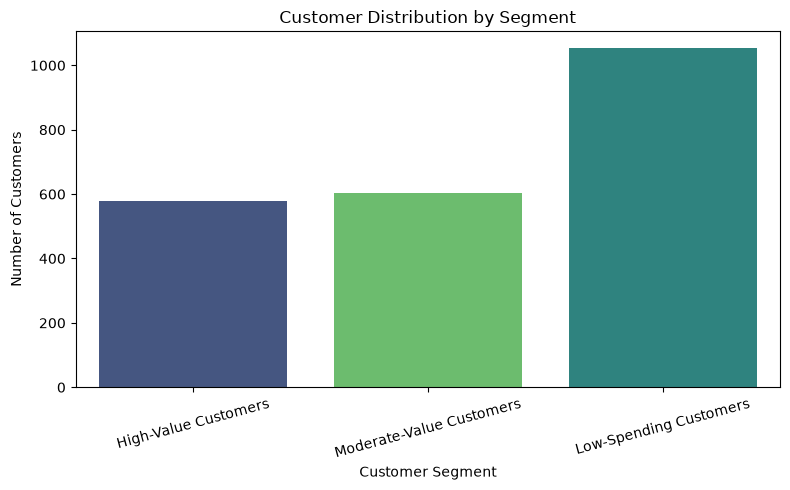

In [72]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.countplot(
    data=customer_segments,
    x='Segment_Name',
    hue='Segment_Name',
    order=[
        'High-Value Customers',
        'Moderate-Value Customers',
        'Low-Spending Customers'
    ],
    palette='viridis',
    legend=False
)

plt.title('Customer Distribution by Segment')
plt.xlabel('Customer Segment')
plt.ylabel('Number of Customers')
plt.xticks(rotation=15)
plt.tight_layout()

plt.show()

In [73]:
#PCA 2D Cluster Visualization
#Step 1 – Apply PCA
from sklearn.decomposition import PCA

pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

print("PCA Shape:", X_pca.shape)

print(
    "Explained Variance Ratio:",
    pca.explained_variance_ratio_
)

print(
    "Total Explained Variance:",
    round(pca.explained_variance_ratio_.sum() * 100, 2),
    "%"
)

PCA Shape: (2236, 2)
Explained Variance Ratio: [0.41010623 0.09427982]
Total Explained Variance: 50.44 %


In [74]:
#Step 2 – Create PCA DataFrame
pca_df = pd.DataFrame(
    X_pca,
    columns=['PC1', 'PC2'],
    index=customer_segments.index
)

pca_df['Segment_Name'] = (
    customer_segments['Segment_Name']
)

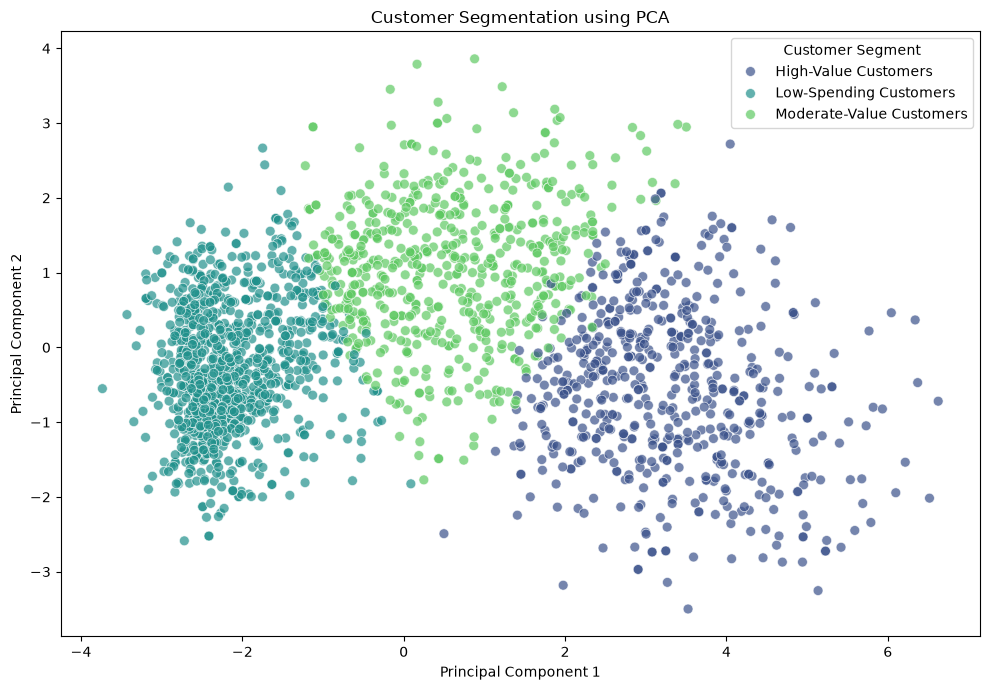

In [75]:
#Step 3 – Plot clusters
plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=pca_df,
    x='PC1',
    y='PC2',
    hue='Segment_Name',
    palette='viridis',
    alpha=0.7,
    s=50
)

plt.title('Customer Segmentation using PCA')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.legend(title='Customer Segment')
plt.tight_layout()

plt.show()